# Building micrograd

**Video:** [The spelled-out intro to neural networks and backpropagation: building micrograd](https://www.youtube.com/watch?v=VMj-3S1tku0)

Micrograd is an **autograd engine** (short for *automatic gradient*). It implements **backpropagation**, an algorithm that lets you efficiently evaluate the gradient of some loss function with respect to the weights of a neural network. That lets us iteratively tune the weights to minimise the loss, and so improve the accuracy of the network. Backpropagation is the mathematical core of any modern deep learning library (e.g. PyTorch).

### The big picture

Micrograd lets you build out mathematical expressions. Backpropagation starts at the output node (e.g. `g`) and goes **backwards** through the expression graph, recursively applying the **chain rule**. This gives the derivative of `g` with respect to all the internal nodes (`c`, `d`, `e`) and also with respect to the inputs (`a`, `b`).

$\frac{\partial g}{\partial a}$ and $\frac{\partial g}{\partial b}$ tell us how `a` and `b` affect `g` through the expression. In the example from the [micrograd README](https://github.com/karpathy/micrograd), $\frac{\partial g}{\partial a} \approx 138.8$: if we nudge `a` slightly upwards, `g` grows, and the slope of that growth is about 138.8. The same goes for `b`.

- **Neural networks are just mathematical expressions.** They take the input data and the weights as inputs, and the output is the network's predictions or the loss.
- **Backpropagation is more general than neural networks.** It works on arbitrary mathematical expressions. We just happen to use it to train neural networks.
- **Micrograd is a scalar-valued engine.** It breaks neural networks all the way down to individual scalars and the little operators on them (`+`, `*`, ...). You'd never do this in production. It's simplified for teaching, so that we don't have to deal with n-dimensional tensors.
- **Tensors are purely for efficiency.** To train bigger networks you package the scalars into tensors (arrays of scalars), so that operations run in parallel and everything is faster. None of the math changes.

> Karpathy's claim: micrograd is all you need to train neural networks, and everything else is just efficiency.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random

%matplotlib inline

## Derivatives of a simple function

A scalar-valued function that takes a single scalar $x$ and returns a single scalar $y$:

$$f(x) = 3x^2 - 4x + 5$$

In [2]:
def f(x):
    return 3 * x**2 - 4 * x + 5

In [3]:
f(3.0)

20.0

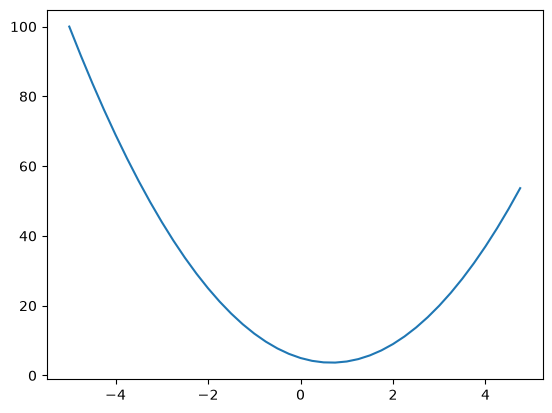

In [4]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

The **derivative** of $f$ at a point $x$ tells us how the function responds when we slightly increase $x$ by a small number $h$: whether it goes up or down, and by how much (the slope at that point).

$$f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}$$

We can estimate this numerically with a small $h$. Here $f'(x) = 6x - 4$, so the slope is 0 at $x = 2/3$.

In [5]:
h = 0.000001
x = 2 / 3  # at this point the slope is 0
(f(x + h) - f(x)) / h

2.999378523327323e-06

Now an expression with three inputs, $d = a \cdot b + c$. Nudging one input by $h$ and seeing how $d$ changes estimates the derivative of $d$ with respect to that input.

In [6]:
# three inputs to the expression graph and a single output d
a = 2.0
b = -3.0
c = 10.0
d = a * b + c
print(d)

4.0


In [7]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a * b + c
c += h
d2 = a * b + c

print("d1", d1)
print("d2", d2)
print("slope", (d2 - d1) / h)  # dd/dc: how fast d increases as we nudge c

d1 4.0
d2 4.0001
slope 0.9999999999976694


## The `Value` object

Now we build the data structure that supports the mathematical operations. Each `Value` stores a scalar (`data`), its gradient (`grad`), the `Value`s it was made from (`_prev`) and the operation that made it (`_op`).

> **Note:** this cell has the **final** version of the class. In the lecture it was built up step by step, so some later cells talk about things the class already has (the `+=` bug fix, `exp`, `/`, `-`, `__radd__`). This cell also redefines `f` as a `Value`, so the function `f(x)` above stops working after it runs.

In [8]:
class Value:
    def __init__(self, data, _children=(), _op="", label=""):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(
            other, (int, float)
        ), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f"**{other}")

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad

        out._backward = _backward
        return out

    def __rmul__(self, other):  # other * self
        return self * other

    def __truediv__(self, other):  # self / other
        return self * other**-1

    def __neg__(self):  # -self
        return self * -1

    def __sub__(self, other):  # self - other
        return self + (-other)

    def __radd__(self, other):  # other + self
        return self + other

    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), "tanh")

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), "exp")

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)

                for child in v._prev:
                    build_topo(child)

                # only added once all of its children have been processed
                topo.append(v)

        build_topo(self)

        self.grad = 1.0

        for node in reversed(topo):
            node._backward()


a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")
e = a * b
e.label = "e"
d = e + c
d.label = "d"
f = Value(-2.0, label="f")
L = d * f
L.label = "L"
L

Value(data=-8.0)

In [9]:
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)

            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)

    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})  # LR = left to right

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))

        # for any value in the graph, create a rectangular ("record") node for it
        dot.node(
            name=uid,
            label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad),
            shape="record",
        )

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)

            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

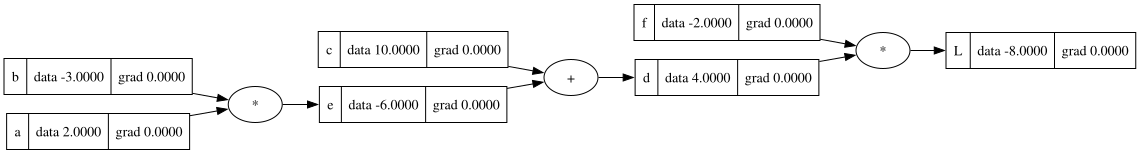

In [10]:
draw_dot(L)

## Manual backpropagation

`grad` is the derivative of the output with respect to each node. It is computed by recursively applying the chain rule **backwards** through the computation graph, towards the children nodes. At each node we already know the derivative of the output with respect to that node. That node was produced by some operation, and we have pointers to the operation's children. We know the **local derivatives** of that operation, so we multiply them onto the derivative we have, and this continues recursively.

**Chain rule:** if $z$ depends on $y$ and $y$ depends on $x$, then

$$\frac{dz}{dx} = \frac{dz}{dy} \cdot \frac{dy}{dx}$$

In [11]:
L.grad = 1.0  # dL/dL = 1
f.grad = 4.0  # dL/df = d
d.grad = -2.0  # dL/dd = f
c.grad = -2.0  # dL/dc = (dL/dd) * (dd/dc) = -2.0 * 1.0
e.grad = -2.0  # dL/de = (dL/dd) * (dd/de) = -2.0 * 1.0
b.grad = -4.0  # dL/db = (dL/de) * (de/db) = -2.0 * a
a.grad = 6.0  # dL/da = (dL/de) * (de/da) = -2.0 * b

A `+` node's local derivatives are just 1. For $d = e + c$, $\frac{\partial d}{\partial e} = \frac{\partial d}{\partial c} = 1$, so in the chain rule the derivative is multiplied by 1. It stays the same and is routed to the children nodes. A `+` node just **distributes** the gradient.

A `*` node's local derivative with respect to one input is the **other** input. For $e = a \cdot b$, $\frac{\partial e}{\partial a} = b$.

Nudging every input a small step in the direction of its gradient should make `L` go up (become less negative). `e`, `d` and `L` are not inputs, so we don't nudge them. We recompute them from the nudged inputs.

In [12]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f

L.data

-7.286496

### Gradient check

A **gradient check** compares the derivatives from backpropagation (computed analytically with the chain rule) with a **numerical gradient**, which estimates the same derivative by nudging an input by a small step $h$:

$$\frac{\partial L}{\partial c} \approx \frac{L(c + h) - L(c)}{h}$$

The function below does this for `c`. The result should match `c.grad = -2.0`.

In [13]:
def lol():
    h = 0.001

    a = Value(2.0, label="a")
    b = Value(-3.0, label="b")
    c = Value(10.0, label="c")
    e = a * b
    e.label = "e"
    d = e + c
    d.label = "d"
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label="a")
    b = Value(-3.0, label="b")
    c = Value(10.0, label="c")
    c.data += h  # below dL / dc is printed
    e = a * b
    e.label = "e"
    d = e + c
    d.label = "d"
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    print((L2 - L1) / h)


lol()

-1.9999999999988916


## A neuron

Neural networks, in the simplest case, are **multilayer perceptrons** (MLPs).

In a simple mathematical model of a neuron, we have some inputs $x_i$ and some synapses with weights $w_i$. The synapses interact with the inputs multiplicatively, so each $w_i x_i$ flows to the cell body. The cell body has a bias $b$. It adds up all the $w_i x_i$ plus the bias, and passes the result through an **activation function**, usually some kind of squashing function (e.g. sigmoid, tanh). So what comes out of the neuron is the activation function applied to the dot product of the weights and inputs, **plus the bias**:

$$o = \tanh\left(\sum_i w_i x_i + b\right)$$

tanh is a squashing activation function: the inputs get squashed on the y coordinate. Very positive inputs are smoothly capped at 1, and very negative ones at -1.

$$\tanh(x) = \frac{e^{2x} - 1}{e^{2x} + 1}$$

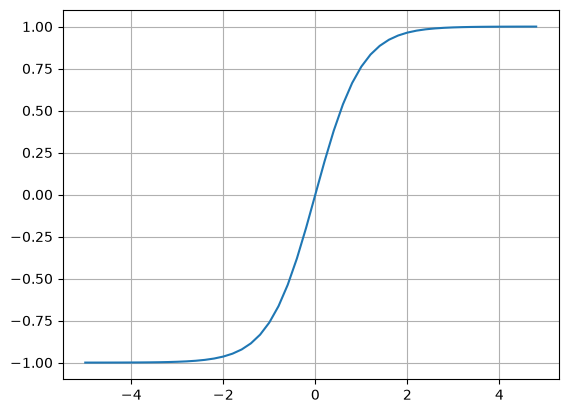

In [14]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)))
plt.grid()

A neuron with 2 inputs. The bias `6.8813...` is chosen so that $n \approx 0.8814$ and $o = \tanh(n) = 1/\sqrt{2} \approx 0.7071$. That makes the numbers nice: $1 - o^2 = 0.5$.

In [15]:
# inputs
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights - synaptic strengths for each input
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# bias of the neuron
b = Value(6.8813735870195432, label="b")

# x1 * w1 + x2 * w2 + b
x1w1 = x1 * w1
x1w1.label = "x1*w1"
x2w2 = x2 * w2
x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b
n.label = "n"

# output via activation function
o = n.tanh()
o.label = "o"

Now we backpropagate by hand, filling in the derivative of `o` with respect to every node. We start at `o` and work backwards.

In a neural network we care most about the derivatives with respect to the **weights**, because those are what we change during optimisation. This is just one neuron. A real network has many connected neurons, and at the end there's a loss function that measures the accuracy of the network. We backpropagate from that loss.

In [16]:
o.grad = 1.0  # do/do = 1
n.grad = 0.5  # do/dn = 1 - tanh(n)**2 = 1 - o**2
x1w1x2w2.grad = 0.5  # + routes the gradient through unchanged
b.grad = 0.5
x1w1.grad = 0.5
x2w2.grad = 0.5
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

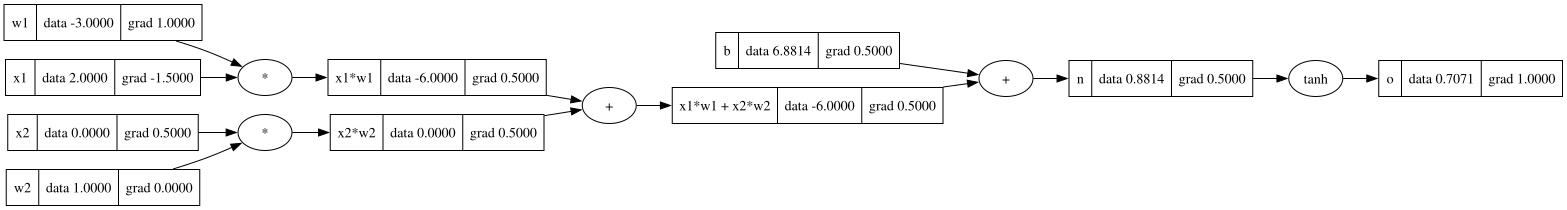

In [17]:
draw_dot(o)

If we want this neuron's output to increase, `w1` should go up: `w1.grad = 1.0`, so locally `o` increases at the same rate as `w1`. `w2` doesn't matter here: `x2 = 0`, so `w2.grad = 0`.

## Automatic backpropagation

Now we automate the same thing using each node's `_backward` function instead of computing gradients by hand.

> Note: `_backward` **accumulates** gradients with `+=` (see the bug section below). So before each new way of running the backward pass, these cells reset the gradients to zero. Without the reset, they'd add up.

In [18]:
# reset the grads set by hand above, since _backward accumulates with +=
for v in [o, n, x1w1x2w2, b, x1w1, x2w2, x1, w1, x2, w2]:
    v.grad = 0.0

o.grad = 1.0
o._backward()
n._backward()
x1w1x2w2._backward()
x2w2._backward()
x1w1._backward()

Next, we stop calling `_backward` by hand. We must never call `_backward` on a node before we've done everything after it: all of its dependencies must have propagated their gradients into it first. That ordering comes from a **topological sort**, which lays out the graph so that all edges go from left to right.

In [19]:
topo = []
visited = set()


def build_topo(v):
    if v not in visited:
        visited.add(v)

        for child in v._prev:
            build_topo(child)

        topo.append(v)  # only added once all of its children have been processed


build_topo(o)
topo

[Value(data=6.881373587019543),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=2.0),
 Value(data=-3.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [20]:
for node in topo:
    node.grad = 0.0  # start again from zero

o.grad = 1.0  # base case

for node in reversed(topo):
    node._backward()

Or just call `backward()`, which does the topological sort and the loop above for us:

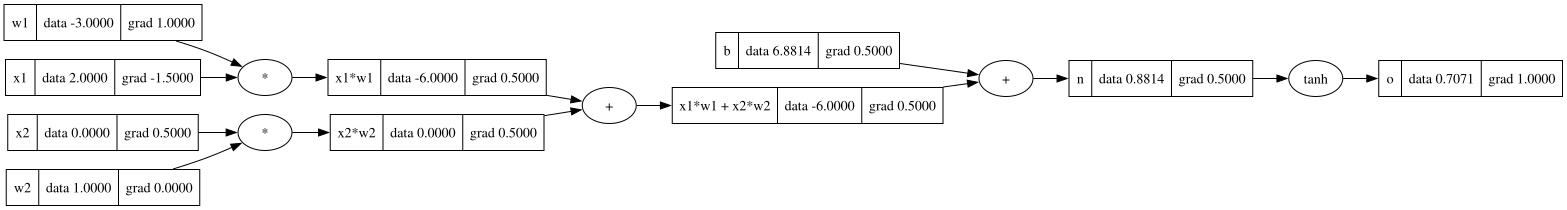

In [21]:
for node in topo:
    node.grad = 0.0  # start again from zero

o.backward()
draw_dot(o)

## Bug: gradients must accumulate

The first version of `_backward` *set* the gradients with `=`. This is the simplest case that shows the bug:

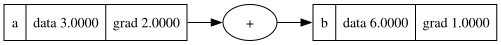

In [22]:
a = Value(3.0, label="a")
b = a + a
b.label = "b"
b.backward()

draw_dot(b)

$b = a + a$, so $\frac{db}{da} = 2$. With `=`, `a.grad` came out as 1. With the fixed class above, it is 2.

Another example:

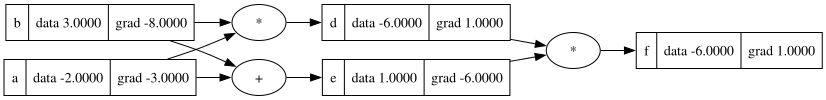

In [23]:
a = Value(-2.0, label="a")
b = Value(3.0, label="b")
d = a * b
d.label = "d"
e = a + b
e.label = "e"
f = d * e
f.label = "f"
f.backward()

draw_dot(f)

With `=`, the gradients of `a` and `b` were wrong here too. The issue shows up whenever a variable is used more than once. Each use backpropagates into the same node, and with `=` a later one **overwrites** the gradient from an earlier one. The fix is to **accumulate** the gradients, so the `_backward` functions use `+=` instead of `=`.

This follows from the multivariable chain rule: if a variable feeds into several nodes, its derivative is the **sum** of the contributions through each path.

## Breaking tanh into smaller operations

We implemented `tanh` as a single operation. We can do that because we know its derivative and can backpropagate through it. But we could also break it into more atomic operations,

$$\tanh(x) = \frac{e^{2x} - 1}{e^{2x} + 1},$$

if `Value` supports `exp`, `/`, `-` and operations with plain numbers. The class above already has all of these. We should get the same results either way.

`2 * a` needs `__rmul__`: Python first tries `int.__mul__(2, a)`, which doesn't know about `Value`, so it falls back to `a.__rmul__(2)`. In the same way, `sum()` needs `__radd__` because it starts from `0`.

In [24]:
a = Value(2.0)
a + 1
a * 2
2 * a
a.exp()

Value(data=7.38905609893065)

Division can be rewritten as $a / b = a \cdot b^{-1}$, so we only need `__pow__` and `__mul__`, not a separate backward pass for division.

In [25]:
a = Value(2.0)
b = Value(4.0)
a / b
a * (b**-1)

Value(data=0.5)

The same neuron as before, but with `tanh` written out using `exp`, `/`, `-` and `+`. The graph is bigger, but `o` and the gradients of the inputs are the same.

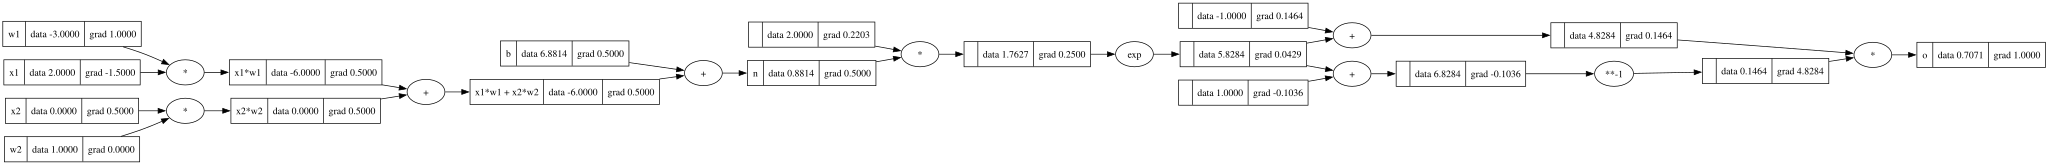

In [26]:
# inputs
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights - synaptic strengths for each input
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# bias of the neuron
b = Value(6.8813735870195432, label="b")

# x1 * w1 + x2 * w2 + b
x1w1 = x1 * w1
x1w1.label = "x1*w1"
x2w2 = x2 * w2
x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b
n.label = "n"

e = (2 * n).exp()
o = (e - 1) / (e + 1)

o.label = "o"
o.backward()

draw_dot(o)

**Takeaway:** the level at which you implement operations is up to you. You can write backward passes for tiny operations like a single `+` or `*`, or for composite ones like `tanh`. All that matters is that you can do the forward pass and the backward pass (the local derivative) of that operation, however composite it is.

## The same thing in PyTorch

Micrograd is a scalar-valued engine, but in PyTorch everything is built around **tensors**: n-dimensional arrays of scalars. Here we create single-element tensors and cast them to `double` (float64). Python floats are double precision and PyTorch's default is float32, so this makes everything match. Leaf tensors need `requires_grad = True`, because by default PyTorch doesn't compute gradients for them (for efficiency).

In [27]:
import torch

x1 = torch.Tensor([2.0]).double()
x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()
x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()
w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()
w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()
b.requires_grad = True

n = x1 * w1 + x2 * w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("---")
print("x2", x2.grad.item())
print("w2", w2.grad.item())
print("x1", x1.grad.item())
print("w1", w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


PyTorch can do what micrograd does, as the special case where all tensors have a single element. The big deal is efficiency: PyTorch works on whole tensors, so lots of operations run in parallel.

> Side note: `o` is `0.70710669` here vs `0.70710678` in micrograd. `torch.Tensor([...])` creates a **float32** tensor first, so the bias is rounded to float32 before `.double()` converts it. `torch.tensor([6.88...], dtype=torch.float64)` would avoid that.

## Building a neural net

Now that we can build pretty complicated mathematical expressions, we can build neural networks, which are just a specific class of mathematical expressions. We build one piece by piece, up to a **multilayer perceptron** (MLP).

First, a single neuron. It's written to match the API of PyTorch's neural network modules, just as `Value` matches PyTorch's autograd API.

In [28]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        # w * x + b
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]


x = [2.0, 3.0]
n = Neuron(2)
n(x)

Value(data=0.09715422873840951)

Next, a **layer**: a set of neurons, each evaluated independently on the same input.

In [29]:
class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]


x = [2.0, 3.0]
n = Layer(2, 3)
n(x)

[Value(data=0.996771690032628),
 Value(data=-0.9234405393147727),
 Value(data=0.6643994764004847)]

Finally, an entire **MLP**, where the layers feed into each other sequentially. `MLP(3, [4, 4, 1])` takes 3 inputs and has two hidden layers of 4 neurons and one output neuron.

In [30]:
class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i + 1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.5859745538312738)

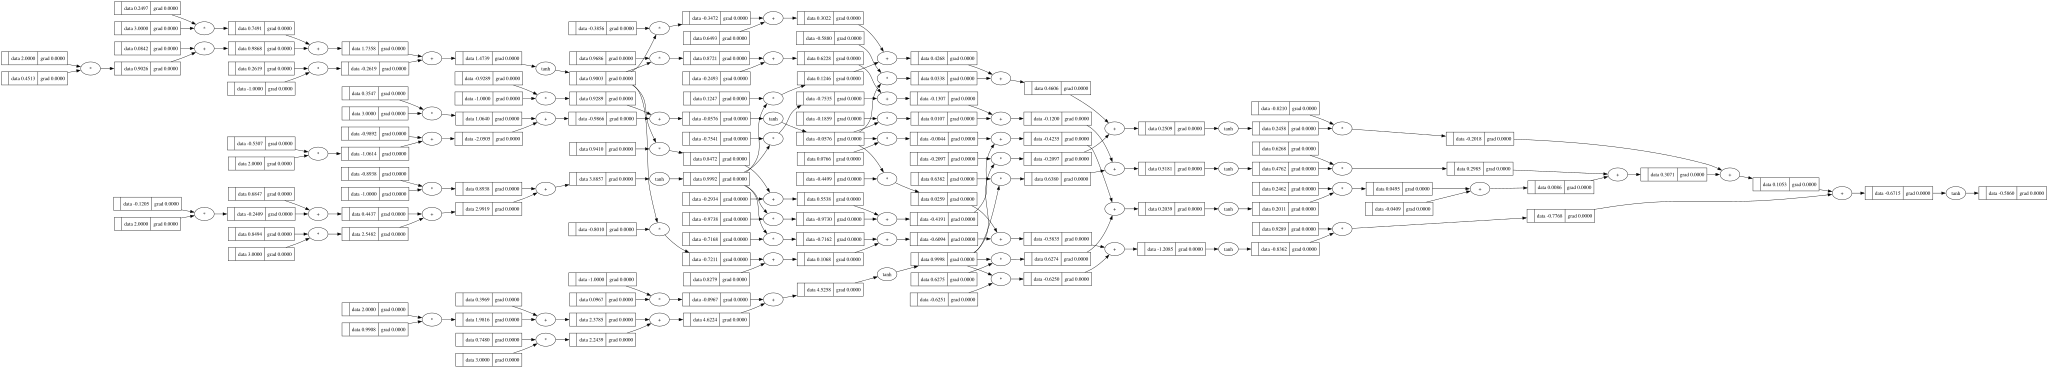

In [31]:
draw_dot(n(x))

## Loss and training

A tiny dataset: 4 inputs, each with a desired target. It's a very simple binary classifier: we want the network to output `1.0` or `-1.0` for each example.

In [32]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]  # desired targets

ypred = [n(x) for x in xs]
ypred

[Value(data=-0.5859745538312738),
 Value(data=0.6549895523849494),
 Value(data=-0.3133459612942429),
 Value(data=-0.7588777766841669)]

We want to tune the weights so the network predicts the targets better. The trick used in deep learning is to compute a single number that measures the total performance of the network, called the **loss**. The predictions aren't close to the targets yet, so the loss is high, and we want to minimise it.

We pair up each ground truth $y_{gt}$ with its prediction $y_{out}$, subtract them, and square. Squaring discards the sign: we get a positive number whether the prediction is too high or too low. (Taking the absolute value would also work.) The loss is the sum of these:

$$L = \sum_i \left(y_{out,i} - y_{gt,i}\right)^2$$

Karpathy calls this the mean squared error (MSE), but strictly it's the **sum** of squared errors. MSE divides by the number of examples. That only scales the gradients, so the minimum is in the same place.

In [33]:
loss = sum((yout - ygt) ** 2 for ygt, yout in zip(ys, ypred))
loss

Value(data=8.819450506088009)

In [34]:
loss.backward()
n.layers[0].neurons[0].w[0].grad

-1.7214030633269997

In [35]:
n.layers[0].neurons[0].w[0].data

0.4512930930253418

If this weight's gradient is positive, increasing the weight would increase the loss, so we want to decrease it. If the gradient is negative, the reverse.

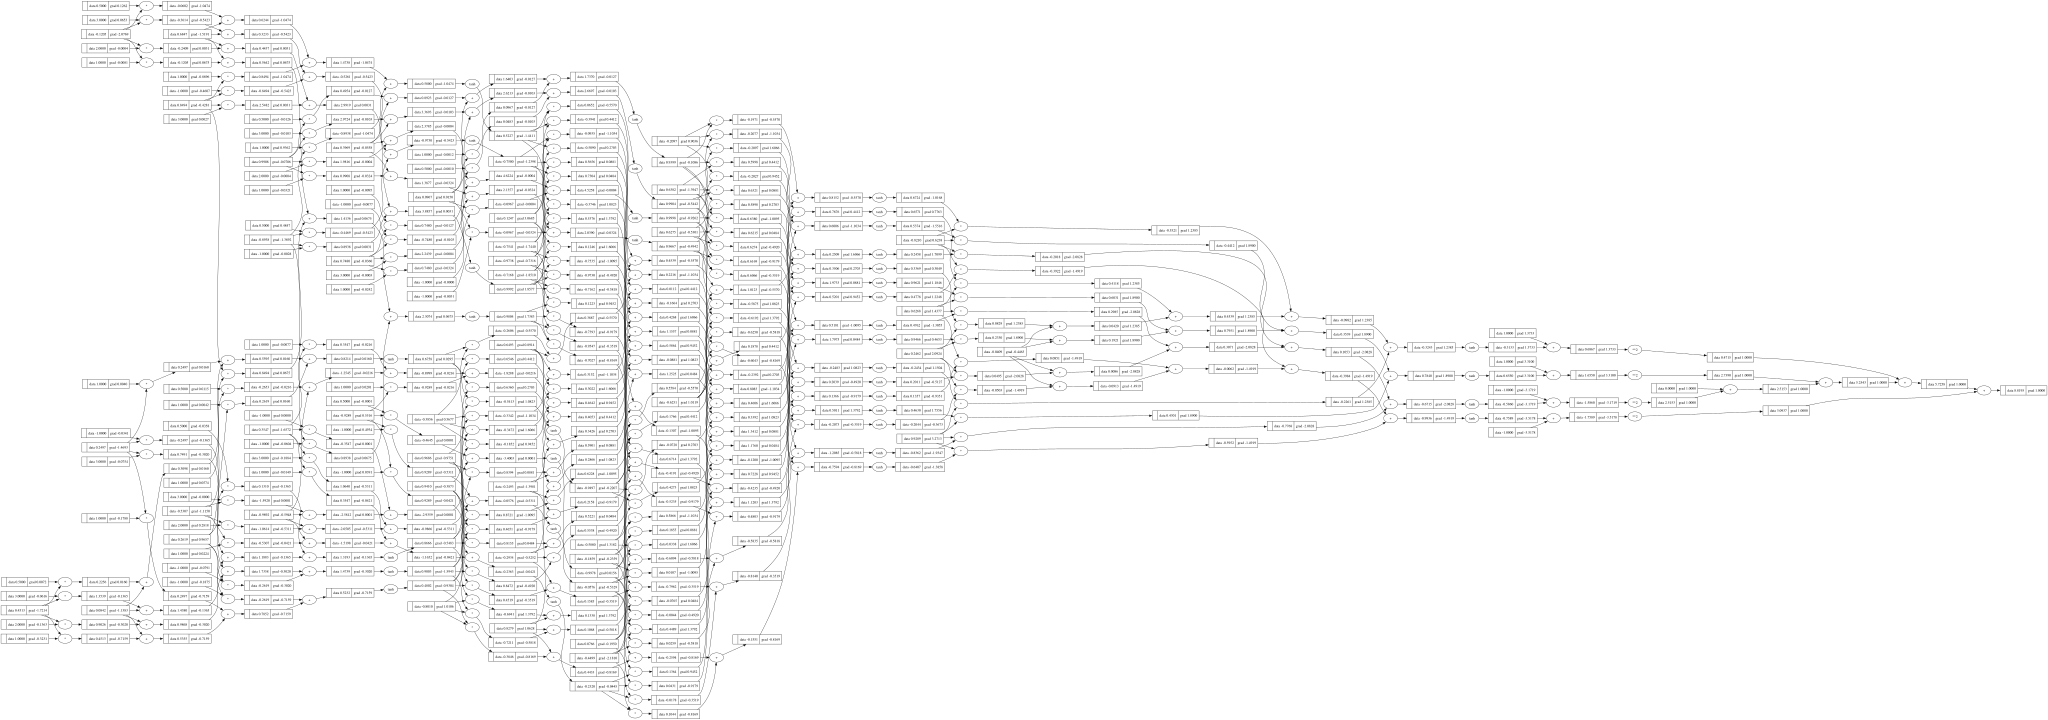

In [36]:
draw_dot(loss)

We need some convenience code to gather up all the parameters of the network (all the weights and biases), so we can nudge every one of them a tiny amount based on its gradient. That's the `parameters()` method. It's already in the `Neuron`, `Layer` and `MLP` cells above, but in the lecture it was added at this point.

In [37]:
n.parameters()

[Value(data=0.4512930930253418),
 Value(data=0.24969839102833435),
 Value(data=0.2619244373280174),
 Value(data=0.08416502456431885),
 Value(data=-0.12046620555475229),
 Value(data=0.8493965316914582),
 Value(data=-0.8938075895844302),
 Value(data=0.6846518779758966),
 Value(data=-0.5306811299401433),
 Value(data=0.3546551368589792),
 Value(data=-0.9289372702822489),
 Value(data=-0.9891679403948981),
 Value(data=0.9908031127225614),
 Value(data=0.7479725858436181),
 Value(data=0.09666979766508699),
 Value(data=0.39691263266029675),
 Value(data=0.9410189951487957),
 Value(data=-0.9737725163088113),
 Value(data=0.07664689991108542),
 Value(data=0.6275422700698241),
 Value(data=-0.29339535019320273),
 Value(data=0.9685981212249717),
 Value(data=-0.7540897373425015),
 Value(data=-0.18594452047629395),
 Value(data=0.6381871916783026),
 Value(data=-0.24928779587026684),
 Value(data=-0.38560778532663353),
 Value(data=0.12470457228874632),
 Value(data=-0.587955108516256),
 Value(data=-0.209711

### Gradient descent

The gradient points in the direction of **increased** loss. To decrease the loss, we move each `p.data` by a small step **against** the gradient:

$$p \leftarrow p - \eta \, \frac{\partial L}{\partial p}$$

where $\eta$ is the step size (learning rate). Gradient descent is just forward pass → backward pass → update, repeated, and the network's predictions improve each time.

In [38]:
for p in n.parameters():
    p.data += -0.01 * p.grad

Now an actual training loop. Every step must reset the gradients to zero before calling `backward()`.

**Why:** the `_backward` functions accumulate with `+=` (needed for nodes that are used more than once), and nothing else resets `grad`. The forward pass builds new intermediate nodes every iteration, so those start at zero. But the parameters are the same `Value` objects every iteration. Without the reset, each `backward()` adds the new gradients onto all the old ones. The update then uses the sum of every gradient so far instead of the current one, which is effectively a much bigger step size than intended.

Karpathy forgets this in the lecture at first ("you forgot to zero grad before that backward"). PyTorch's equivalent is `zero_grad()`.

In [39]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt) ** 2 for ygt, yout in zip(ys, ypred))

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)

0 8.059322939996669
1 3.4039145933609305
2 1.31710954091235
3 0.8170747340642888
4 0.5536027050690897
5 0.4167735461354363
6 0.33465750295333746
7 0.2782198431171919
8 0.23723733053596258
9 0.20626729895629195
10 0.18211798457985132
11 0.16280566342964842
12 0.14703800320974686
13 0.13393972987371922
14 0.12289840787305265
15 0.11347349053831837
16 0.10534045394206137
17 0.09825525791881196
18 0.09203104002681164
19 0.08652241907116615


The loss is now very low, so we expect `ypred` to be close to the targets `[1, -1, -1, 1]`.

In [40]:
ypred

[Value(data=0.8758643939046307),
 Value(data=-0.8670082316647983),
 Value(data=-0.8438768015833625),
 Value(data=0.8295549741361258)]

## Summary

- Neural networks are mathematical expressions (fairly simple ones, in the case of an MLP). They take the data and the weights as inputs. The forward pass is followed by a **loss function**, which measures the accuracy of the predictions. It's set up so that the loss is low when the network does what we want.
- We **backpropagate** from the loss to get the gradient, which tells us how to tune every parameter to decrease the loss locally.
- We repeat this many times: **gradient descent**. We follow the gradient to minimise the loss, and minimising the loss makes the network do what we want.
- This model is tiny, but the same principles hold for networks with billions or even trillions of parameters: a massive blob of simulated neural tissue, roughly speaking, which can solve very complex problems and has fascinating emergent properties. GPT, for example, is trained on massive amounts of internet text to take some words and predict the next word in the sequence.
- Those networks work fundamentally the same way: evaluate the gradient, then do gradient descent. They use a slightly different parameter update (here we used the simplest possible gradient descent update) and, for predicting the next token, **cross-entropy** loss instead of squared error.

**Batches:** our dataset is tiny, so every step does a forward pass on all of it. With, say, a million examples, in practice we pick out a random subset called a **batch** and only do forward → backward → update on that batch, so we don't have to run the whole training set every step.